<a href="https://colab.research.google.com/github/Prajwaln08/SQLSmith/blob/main/notebooks/06_Full_Spider_Benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SQLSmith — Notebook 06 | Full Spider 1.0 Development Benchmark

**Milestone A.1** · 1,034 Spider development examples · Qwen2.5-Coder **1.5B** and **7B** · official augmented test-suite evaluation.

This notebook extends the earlier 50-example research demonstration to all Spider 1.0 development examples. It **does not** train a model or use development-set gold SQL during generation. Inference uses each question and its public schema only.

### Execution plan

1. Run setup and freeze the development set.
2. Select `MODEL_CHOICE = "1.5b"` in the configuration cell, load that model, and run/resume generation until complete.
3. Change `MODEL_CHOICE = "7b"`; **restart the Colab runtime**, then run setup and generation again for the other model.
4. After both prediction files exist, run the **CPU-only evaluation/reporting section** (a fresh CPU runtime is fine).

**Use T4 GPU for generation.** The first 50 questions are regenerated into *new, isolated full-dev artifacts*, not copied from the old experiment. The test suite is the unchanged ZIP you previously stored in Drive. Cloud Colab is used only for public Spider data; do not upload any regulated production schema/data.

**Folder:** `/content/drive/MyDrive/Prajwal/Projects/SQLSmith/`.

> Reproducibility limitations: some GPU/kernel operations are not strictly bitwise reproducible between Colab sessions, even with deterministic decoding. Save model revision, environment versions and individual predictions. Results are development-set metrics, not independent production/generalization claims.

## 1 — Install the inference dependencies
Run once in a fresh Colab session **before importing transformers**. If you upgrade already-imported packages, restart the runtime. For scoring only (CPU), you can skip the GPU cells.

In [1]:
%pip install -q -U "transformers>=4.48,<5" "accelerate>=1.0" "bitsandbytes>=0.46.1" huggingface_hub pandas numpy nltk sqlglot

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.5 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
ibis-framework 9.5.0 requires sqlglot<25.21,>=23.4, but you have sqlglot 30.33.0 which is incompatible.


## 2 — Drive and common paths

In [2]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import json, csv, hashlib, os, sys, subprocess, zipfile, time, re, gc, statistics
import pandas as pd
import numpy as np

drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/Prajwal/Projects/SQLSmith')
RESULTS = PROJECT / 'results'
FULL = RESULTS / 'full_spider'
EVAL = PROJECT / 'evaluation' / 'spider_full'
DATA = PROJECT / 'data'
for p in (RESULTS, FULL, EVAL, DATA): p.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()

print('Drive results:', FULL)
print('Python:', sys.version.split()[0])

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Mounted at /content/drive
Drive results: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/full_spider
Python: 3.13.18


## 3 — Load and fingerprint original Spider 1.0 dev metadata
The ZIP archive checksum is pinned to the package used for Notebooks 01–04. The first 50 examples will be cross-checked against the prior frozen CSV.

In [3]:
from huggingface_hub import hf_hub_download
SPIDER = Path('/content/sqlsmith_data/spider_data')
ARCHIVE = hf_hub_download(repo_id='HAL-9001/spider-databases', repo_type='dataset', filename='spider_data.zip')
EXPECTED_SPIDER_ZIP_HASH = '00636695dabed6b5f4b8328a16b13e069a2f16591d5efcce57660669c85b121b'
assert sha256_file(ARCHIVE) == EXPECTED_SPIDER_ZIP_HASH, 'Spider archive differs from the original benchmark package.'
if not all((SPIDER / name).is_file() for name in ('dev.json','tables.json')):
    root = Path('/content/sqlsmith_data').resolve()
    root.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARCHIVE) as z:
        for item in z.infolist():
            assert (root / item.filename).resolve().is_relative_to(root), 'Unsafe archive path'
            assert not item.filename.startswith('/'), 'Absolute archive path'
        z.extractall(root)
DEV_PATH = SPIDER / 'dev.json'
TABLES_PATH = SPIDER / 'tables.json'
dev = json.loads(DEV_PATH.read_text(encoding='utf-8'))
schemas = {s['db_id']:s for s in json.loads(TABLES_PATH.read_text(encoding='utf-8'))}
assert len(dev) == 1034, f'Expected 1034 Spider dev examples, got {len(dev)}'
assert all(item['db_id'] in schemas for item in dev)

dev_df = pd.DataFrame([{'index':i+1,'db_id':r['db_id'],'question':r['question'],'gold_sql':r['query']} for i,r in enumerate(dev)])
assert dev_df['index'].is_unique
OLD_1B = RESULTS / 'spider_1_5b_baseline_50.csv'
if OLD_1B.is_file():
    old = pd.read_csv(OLD_1B, keep_default_na=False).sort_values('index')
    assert len(old) == 50
    for _, row in old.iterrows():
        ref = dev[int(row['index'])-1]
        assert row['db_id'] == ref['db_id'] and row['question'].strip() == ref['question'].strip()
        assert ' '.join(str(row['gold_sql']).split()) == ' '.join(ref['query'].split())
    print('PASS: First 50 match earlier experiment inputs.')
print('Spider dev questions:',len(dev),'distinct databases:',dev_df.db_id.nunique())
print('dev.json sha:',sha256_file(DEV_PATH))
print('tables.json sha:',sha256_file(TABLES_PATH))
display(dev_df[['index','db_id','question']].head(4))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


spider_data.zip:   0%|          | 0.00/206M [00:00<?, ?B/s]

PASS: First 50 match earlier experiment inputs.
Spider dev questions: 1034 distinct databases: 20
dev.json sha: 30d64a3fccde493226df79687aed9e4a1c0129525baf44f29c0573d914d758a4
tables.json sha: 61bb20aa401f03164e2d7f3b16509b7b5f79cc9c943ca7bd159046df1159e2ed


,index,db_id,question
0,1,concert_singer,How many singers do we have?
1,2,concert_singer,What is the total number of singers?
2,3,concert_singer,"Show name, country, age for all singers ordere..."
3,4,concert_singer,"What are the names, countries, and ages for ev..."


## 4 — Freeze the original full-schema formatter and generation prompt
This is the same **full-schema** representation and chat wording used for the earlier baselines. It deliberately does *not* add schema linking, repair, examples or training-derived improvements.

In [4]:
def get_spider_schema(db_id):
    item = schemas[db_id]
    tables = item['table_names_original']
    columns = item['column_names_original']
    types = item['column_types']
    output = []
    for table_index, table_name in enumerate(tables):
        table_columns = []
        for col_index, (idx, col_name) in enumerate(columns):
            if idx == table_index:
                table_columns.append(f'  {col_name} {types[col_index]}')
        output.append(f'Table: {table_name}\n' + '\n'.join(table_columns))
    output.append('\nForeign keys:')
    for col_a, col_b in item['foreign_keys']:
        ta, ca = columns[col_a]
        tb, cb = columns[col_b]
        if ta >= 0 and tb >= 0:
            output.append(f'{tables[ta]}.{ca} = {tables[tb]}.{cb}')
    return '\n\n'.join(output)

SYSTEM_PROMPT = ('You are an expert text-to-SQL assistant. '
                 'Generate exactly one valid SQLite SELECT query. '
                 'Use only the tables and columns in the schema. '
                 'Return SQL only, without markdown or explanation.')
def make_messages(question, schema_text):
    return [
        {'role':'system','content':SYSTEM_PROMPT},
        {'role':'user','content':f'Schema:\n{schema_text}\n\nQuestion: {question}'}
    ]

print('Schema preview:')
print(get_spider_schema(dev[0]['db_id'])[:1100])

Schema preview:
Table: stadium
  Stadium_ID number
  Location text
  Name text
  Capacity number
  Highest number
  Lowest number
  Average number

Table: singer
  Singer_ID number
  Name text
  Country text
  Song_Name text
  Song_release_year text
  Age number
  Is_male others

Table: concert
  concert_ID number
  concert_Name text
  Theme text
  Stadium_ID text
  Year text

Table: singer_in_concert
  concert_ID number
  Singer_ID text


Foreign keys:

concert.Stadium_ID = stadium.Stadium_ID

singer_in_concert.Singer_ID = singer.Singer_ID

singer_in_concert.concert_ID = concert.concert_ID


## 5 — Choose a model to benchmark

Use `MODEL_CHOICE = '1.5b'` first. Once you finish and verify its output, restart runtime and switch it to `'7b'`. This notebook intentionally does **not** automatically load both models in one session.

**Important:** `START_INDEX` / `END_INDEX` allow a *pilot run* without deleting anything. A full score is blocked until all 1034 predictions exist. Keep the same config, prompt and max tokens across sessions. Restarting only resets runtime memory, not checkpoints on Drive.

In [5]:
MODEL_CHOICE = '7b'     # Change to '7b' on your SECOND complete run
START_INDEX = 1           # inclusive, for pilots/resume
END_INDEX = 1034          # inclusive; 1034 for a complete run
MAX_NEW_TOKENS = 256

MODEL_IDS = {'1.5b':'Qwen/Qwen2.5-Coder-1.5B-Instruct',
             '7b':'Qwen/Qwen2.5-Coder-7B-Instruct'}
assert MODEL_CHOICE in MODEL_IDS
assert 1 <= START_INDEX <= END_INDEX <= len(dev)
MODEL_ID = MODEL_IDS[MODEL_CHOICE]
CHECKPOINT = FULL / f'spider_{MODEL_CHOICE}_full_dev_checkpoint.jsonl'
CONFIG_PATH = FULL / f'spider_{MODEL_CHOICE}_full_dev_config.json'
OUT_CSV = FULL / f'spider_{MODEL_CHOICE}_full_dev_predictions.csv'

CONFIG = dict(model=MODEL_ID, quantization='4bit_nf4', double_quant=False,
    compute_dtype='float16', max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
    prompt_revision='notebook01_full_schema_original',
    spider_dev_sha256=sha256_file(DEV_PATH),
    tables_sha256=sha256_file(TABLES_PATH),
    dataset='Spider 1.0 dev all 1034', schema_format='full',
    source_50_reference_sha256=sha256_file(OLD_1B) if OLD_1B.is_file() else None)
if CONFIG_PATH.exists():
    existing = json.loads(CONFIG_PATH.read_text(encoding='utf-8'))
    assert existing == CONFIG, 'Experiment config changed. Do not mix checkpoints; archive/rename old run first.'
else:
    assert not CHECKPOINT.exists(), 'Checkpoint found without config. Inspect before continuing.'
    CONFIG_PATH.write_text(json.dumps(CONFIG,indent=2),encoding='utf-8')
print('Model:',MODEL_ID,'range:',START_INDEX,'to',END_INDEX)
print('Checkpoint:', CHECKPOINT)
print('Config:',CONFIG_PATH)

Model: Qwen/Qwen2.5-Coder-7B-Instruct range: 1 to 1034
Checkpoint: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/full_spider/spider_7b_full_dev_checkpoint.jsonl
Config: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/full_spider/spider_7b_full_dev_config.json


## 6 — Load the selected model on the T4 GPU

Run this cell only for generation. If `bitsandbytes` reports missing or incompatible dependencies, restart session, rerun the package cell, and then rerun setup. Do not enable CPU offloading: it invalidates the T4-only latency benchmark.

In [6]:
import torch, importlib.metadata
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
assert torch.cuda.is_available(), 'Enable a T4 GPU: Runtime > Change runtime type.'
print('GPU:',torch.cuda.get_device_name(0),'PyTorch:',torch.__version__,
      'Transformers:',importlib.metadata.version('transformers'),
      'bitsandbytes:',importlib.metadata.version('bitsandbytes'))
if 'model' in globals():
    del model
    gc.collect()
    torch.cuda.empty_cache()

qconfig = BitsAndBytesConfig(load_in_4bit=True,
    bnb_4bit_quant_type='nf4',bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=False)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, quantization_config=qconfig, device_map='auto',
    dtype=torch.float16, low_cpu_mem_usage=True)
model.eval()
assert all(str(d) != 'cpu' for d in model.hf_device_map.values()), 'CPU offload detected'
print('Loaded:',MODEL_ID)
print('Allocated GiB:',round(torch.cuda.memory_allocated()/2**30,3))
print('Device map:',model.hf_device_map)

# Record environment without requiring a perfectly identical Colab image later.
ENV_PATH = FULL / f'spider_{MODEL_CHOICE}_environment.json'
ENV_PATH.write_text(json.dumps({'model':MODEL_ID,
    'python':sys.version.split()[0], 'torch':torch.__version__,
    'transformers':importlib.metadata.version('transformers'),
    'accelerate':importlib.metadata.version('accelerate'),
    'bitsandbytes':importlib.metadata.version('bitsandbytes'),
    'gpu':torch.cuda.get_device_name(0),
    'timestamp_utc':datetime.now(timezone.utc).isoformat()},indent=2),encoding='utf-8')

GPU: Tesla T4 PyTorch: 2.14.1+cu130 Transformers: 4.57.6 bitsandbytes: 0.50.2


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

... (6 outputs left out)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded: Qwen/Qwen2.5-Coder-7B-Instruct
Allocated GiB: 5.455
Device map: {'': 0}


255

## 7 — Generation and append-only persistent checkpoint

- One question at a time; never show gold SQL in the prompt.
- No model SQL repair. A failure is logged; rerun this cell to retry only that failed question.
- A completed question is skipped on resume **only if its saved question and database ID still match**.
- Every record is synced to Drive before moving to the next question.
- No per-question SQL execution is performed during generation. Official scoring happens later.

In [7]:
def generate_spider_sql(question, schema_text):
    prompt = tokenizer.apply_chat_template(
        make_messages(question, schema_text), tokenize=False,
        add_generation_prompt=True)
    batch = tokenizer(prompt,return_tensors='pt',add_special_tokens=False)
    ids = batch['input_ids'].to(model.device)
    mask = batch['attention_mask'].to(model.device)
    torch.cuda.synchronize()
    started = time.perf_counter()
    with torch.inference_mode():
        output = model.generate(input_ids=ids, attention_mask=mask,
            max_new_tokens=MAX_NEW_TOKENS,do_sample=False,
            pad_token_id=tokenizer.eos_token_id)
    torch.cuda.synchronize()
    elapsed = time.perf_counter()-started
    tokens = output[0,ids.shape[-1]:]
    sql = tokenizer.decode(tokens,skip_special_tokens=True).strip()
    return sql, elapsed, int(tokens.numel()), int(ids.shape[-1])


def load_completed_checkpoint(path, expected_model):
    done = {}
    if not path.is_file(): return done
    with path.open(encoding='utf-8') as f:
        for number,line in enumerate(f,1):
            if not line.strip(): continue
            try: r = json.loads(line)
            except json.JSONDecodeError:
                print('Warning: incomplete checkpoint line',number,'(ignored)')
                continue
            idx=int(r['index'])
            assert 1<=idx<=len(dev),f'Unexpected index {idx}'
            expected=dev[idx-1]
            assert r['db_id']==expected['db_id'] and r['question']==expected['question']
            assert r.get('model')==expected_model, 'Mixed model checkpoint detected'
            if r.get('status')=='ok':
                assert isinstance(r.get('predicted_sql'),str),f'Non-text SQL at {idx}'
                done[idx]=r
    return done

completed = load_completed_checkpoint(CHECKPOINT, MODEL_ID)
print(f'Found {len(completed)}/{len(dev)} saved {MODEL_CHOICE} predictions')

for idx in range(START_INDEX,END_INDEX+1):
    if idx in completed:
        if idx%25==0: print(f'[{idx}/{END_INDEX}] already saved')
        continue
    item=dev[idx-1]
    try:
        sql, seconds, out_tokens, in_tokens = generate_spider_sql(
            item['question'], get_spider_schema(item['db_id']))
        r={'index':idx,'db_id':item['db_id'],'question':item['question'],
           'predicted_sql':sql,'latency_seconds':round(seconds,6),
           'output_tokens':out_tokens,'input_tokens':in_tokens,
           'model':MODEL_ID,'status':'ok','error':'',
           'created_utc':datetime.now(timezone.utc).isoformat()}
    except Exception as exc:
        r={'index':idx,'db_id':item['db_id'],'question':item['question'],
           'predicted_sql':'','latency_seconds':None,'output_tokens':None,
           'input_tokens':None,'model':MODEL_ID,'status':'error',
           'error':repr(exc),'created_utc':datetime.now(timezone.utc).isoformat()}
    with CHECKPOINT.open('a',encoding='utf-8') as f:
        f.write(json.dumps(r,ensure_ascii=False)+'\n')
        f.flush()
        os.fsync(f.fileno())
    if r['status']!='ok':
        raise RuntimeError(f'Generation stopped at question {idx}; saved error: {r["error"]}')
    completed[idx]=r
    if idx<=5 or idx%10==0 or idx==END_INDEX:
        print(f'[{idx}/{END_INDEX}] saved; {r["latency_seconds"]:.2f}s; {out_tokens} generated tokens')

print(f'Checkpoint progress: {len(completed)}/{len(dev)} for {MODEL_CHOICE}')

Found 0/1034 saved 7b predictions


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[1/1034] saved; 8.02s; 6 generated tokens
[2/1034] saved; 0.50s; 6 generated tokens
[3/1034] saved; 0.81s; 13 generated tokens
[4/1034] saved; 0.83s; 13 generated tokens
[5/1034] saved; 1.24s; 22 generated tokens
[10/1034] saved; 0.91s; 12 generated tokens
[20/1034] saved; 2.94s; 50 generated tokens
[30/1034] saved; 1.05s; 17 generated tokens
[40/1034] saved; 1.13s; 15 generated tokens
[50/1034] saved; 0.86s; 13 generated tokens
[60/1034] saved; 6.58s; 116 generated tokens
[70/1034] saved; 1.01s; 14 generated tokens
[80/1034] saved; 2.51s; 45 generated tokens
[90/1034] saved; 2.73s; 49 generated tokens
[100/1034] saved; 2.64s; 39 generated tokens
[110/1034] saved; 2.53s; 38 generated tokens
[120/1034] saved; 1.51s; 24 generated tokens
[130/1034] saved; 4.02s; 62 generated tokens
[140/1034] saved; 1.31s; 19 generated tokens
[150/1034] saved; 2.91s; 46 generated tokens
[160/1034] saved; 1.40s; 22 generated tokens
[170/1034] saved; 1.76s; 24 generated tokens
[180/1034] saved; 2.26s; 40 ge

## 8 — Export predictions and performance metrics for the selected model

This cell may be rerun after any generation session. If only a pilot subset has finished, it will save a **partial** CSV and will NOT mark the full benchmark complete. Empty SQL text is preserved as a failed model answer, not replaced by reference SQL.

In [8]:
completed = load_completed_checkpoint(CHECKPOINT, MODEL_ID)
rows=[]
for idx in sorted(completed):
    r=completed[idx]
    rows.append({'index':idx,'db_id':r['db_id'],'question':r['question'],
      'gold_sql':dev[idx-1]['query'],'predicted_sql':r['predicted_sql'],
      'latency_seconds':r['latency_seconds'],'output_tokens':r['output_tokens'],
      'input_tokens':r['input_tokens'],'model':MODEL_ID})
result_df=pd.DataFrame(rows)
assert result_df['index'].is_unique if len(result_df) else True
result_df.to_csv(OUT_CSV,index=False)
if len(result_df):
    lat=pd.to_numeric(result_df['latency_seconds'],errors='coerce')
    tps=pd.to_numeric(result_df['output_tokens'],errors='coerce')/lat
    print('Mean latency:',round(lat.mean(),3),'s')
    print('p95 latency:',round(lat.quantile(.95),3),'s')
    print('Mean generated tokens/s:',round(tps.mean(),2))
    print('Peak allocated GPU memory (GiB):',round(torch.cuda.max_memory_allocated()/2**30,3))
print('Rows exported:',len(result_df),'of 1034; fully complete:',len(result_df)==1034)
print('Saved:',OUT_CSV)
print('SHA256:',sha256_file(OUT_CSV))
assert len(result_df)<=1034

Mean latency: 1.904 s
p95 latency: 3.666 s
Mean generated tokens/s: 14.98
Peak allocated GPU memory (GiB): 6.584
Rows exported: 1034 of 1034; fully complete: True
Saved: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/full_spider/spider_7b_full_dev_predictions.csv
SHA256: efde8106130ae3dea89d4dbc4f53151a2371920f69cdf126385ec22ec9b7e610


## 9 — Verification gate: both complete prediction files

When you've finished both models, switch to a **CPU runtime**, then run the common setup (Cells 2–4) and **this cell onward**. You do not need the T4 or loaded models to score SQL. The following code checks full coverage and references before running the official evaluator.

In [6]:

# SQLSmith — CPU-only evaluation configuration

MODEL_IDS = {
    "1.5b": "Qwen/Qwen2.5-Coder-1.5B-Instruct",
    "7b": "Qwen/Qwen2.5-Coder-7B-Instruct"
}

PRED_CSVS = {
    key: FULL / f"spider_{key}_full_dev_predictions.csv"
    for key in MODEL_IDS
}

print("Evaluation configuration initialized.")

for key, path in PRED_CSVS.items():
    assert path.is_file(), f"Missing predictions: {path}"
    print(f"{key}: FOUND — {path.name}")

print("Both models ready for CPU-only evaluation.")


Evaluation configuration initialized.
1.5b: FOUND — spider_1.5b_full_dev_predictions.csv
7b: FOUND — spider_7b_full_dev_predictions.csv
Both models ready for CPU-only evaluation.


In [7]:
PRED_CSVS = {k:FULL / f'spider_{k}_full_dev_predictions.csv' for k in ('1.5b','7b')}
PRED_DFS = {}
for key,path in PRED_CSVS.items():
    assert path.exists(),f'Missing model CSV: {path}'
    frame=pd.read_csv(path,keep_default_na=False)
    assert len(frame)==1034, f'{key} only has {len(frame)}/1034 predictions — finish generation before scoring.'
    frame['index']=pd.to_numeric(frame['index'],errors='raise').astype(int)
    frame=frame.sort_values('index').reset_index(drop=True)
    assert frame['index'].tolist()==list(range(1,1035))
    assert frame['index'].is_unique
    for i,r in frame.iterrows():
        original=dev[i]
        assert r['db_id']==original['db_id'] and r['question']==original['question']
        assert ' '.join(str(r['gold_sql']).split())==' '.join(original['query'].split())
    assert frame['model'].eq(MODEL_IDS[key]).all(),f'Model metadata mismatch: {key}'
    PRED_DFS[key]=frame
    print('PASS',key,'1034 aligned predictions; sha256',sha256_file(path))
assert PRED_DFS['1.5b']['db_id'].equals(PRED_DFS['7b']['db_id'])
print('All predictions aligned to the same full Spider dev set.')

PASS 1.5b 1034 aligned predictions; sha256 144e3f94ed55b3562f4cb9a73db9f0faa470407837ba983c90a4f2475fe86191
PASS 7b 1034 aligned predictions; sha256 efde8106130ae3dea89d4dbc4f53151a2371920f69cdf126385ec22ec9b7e610
All predictions aligned to the same full Spider dev set.


## 10 — Prepare official Spider test-suite databases and evaluator

Reuses the official archive already stored in Drive, avoiding the public Google Drive download limit. The ZIP should contain the augmented SQLite files. The evaluator is pinned to the same commit used in Notebooks 03–04. If the test suite is missing, generation artifacts remain saved.

In [8]:
import nltk
nltk.download('punkt',quiet=True)
nltk.download('punkt_tab',quiet=True)
assert nltk.data.find('tokenizers/punkt_tab/english/')
EVALUATOR_REPO = Path('/content/test-suite-sql-eval')
EVALUATOR_COMMIT = 'e97acc546ecbee8fa27fa8dbf025ef61493a876c'
if not (EVALUATOR_REPO / '.git').is_dir():
    subprocess.run(['git','clone','https://github.com/taoyds/test-suite-sql-eval.git',str(EVALUATOR_REPO)],check=True)
subprocess.run(['git','-C',str(EVALUATOR_REPO),'checkout','--detach',EVALUATOR_COMMIT],check=True)
assert subprocess.check_output(['git','-C',str(EVALUATOR_REPO),'rev-parse','HEAD'],text=True).strip()==EVALUATOR_COMMIT

DRIVE_ZIP = DATA / 'testsuitedatabases.zip'
LOCAL_ZIP = Path('/content/testsuitedatabases.zip')
ZIP = DRIVE_ZIP if DRIVE_ZIP.is_file() else LOCAL_ZIP
assert ZIP.is_file(),f'Test-suite ZIP missing at {DRIVE_ZIP} (or {LOCAL_ZIP})'
assert zipfile.is_zipfile(ZIP)
SUITES = Path('/content/sqlsmith_test_suites')
SUITES.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile(ZIP) as z:
    root=SUITES.resolve()
    for item in z.infolist():
        assert (root/item.filename).resolve().is_relative_to(root),'Unsafe archive entry'
    z.extractall(root)
required_ids=set(dev_df.db_id)
possible=[]
for anchor in list(required_ids)[:5]:
    for f in SUITES.rglob(f'{anchor}.sqlite'):
        if f.parent.name!=anchor: continue
        base=f.parent.parent
        if all((base/d/f'{d}.sqlite').is_file() for d in required_ids):
            possible.append(base)
assert possible, 'Could not find ALL dev DB IDs in extracted test-suite package.'
def suite_count(base): return sum(len(list((base/d).glob('*.sqlite'))) for d in required_ids)
SUITE_DB_ROOT=max(possible,key=suite_count)
suite_counts={d:len(list((SUITE_DB_ROOT/d).glob('*.sqlite'))) for d in sorted(required_ids)}
assert all(v>=1 for v in suite_counts.values())
assert sum(v>1 for v in suite_counts.values())>1,'Augmented database instances not found'
print('Test-suite root:',SUITE_DB_ROOT)
print('Databases:',len(suite_counts),'Augmented (>1 file):',sum(v>1 for v in suite_counts.values()))
print('ZIP sha256:',sha256_file(ZIP))
print('Evaluator commit:',EVALUATOR_COMMIT)

Test-suite root: /content/sqlsmith_test_suites/database
Databases: 20 Augmented (>1 file): 20
ZIP sha256: 9ec24ea8debc6bd04abfe137b5f1a739b5a8836f32c0464e4dfc94eb7f41da96
Evaluator commit: e97acc546ecbee8fa27fa8dbf025ef61493a876c


## 11 — Write the exact same gold SQL to both evaluation runs

One canonical gold file is written from **Spider dev metadata**, not from either model. Prediction files contain 1,034 rows each, in development-set order. This prevents the earlier Notebook 04 gold-hash mismatch.

In [9]:
def one_line(value):
    return ' '.join(str(value).split())
GOLD=EVAL/'spider_full_gold.txt'
gold_lines=[one_line(r['query'])+'\t'+r['db_id'] for r in dev]
assert len(gold_lines)==1034
GOLD.write_text('\n'.join(gold_lines)+'\n',encoding='utf-8')
PRED_FILES={}
for k,frame in PRED_DFS.items():
    dest=EVAL/f'spider_full_predictions_{k}.txt'
    sql=[one_line(x) for x in frame['predicted_sql']]
    # Empty model output stays empty and should count as incorrect, never patched with gold SQL.
    assert len(sql)==1034
    dest.write_text('\n'.join(sql)+'\n',encoding='utf-8')
    PRED_FILES[k]=dest
    print(k,'prediction hash:',sha256_file(dest),'empty predictions:',sum(not x for x in sql))
print('Gold hash (both models):',sha256_file(GOLD))

1.5b prediction hash: 3b8ada69c9eca989e6e7e907d065a297a0d0e24eb09be2fd5746195aedf0f96a empty predictions: 0
7b prediction hash: 52c405da8ee9ca4b84e63f390dbf54d7f9571f53983bf08beca4bbac0f0b7b73 empty predictions: 0
Gold hash (both models): 3d941fdb2e6f330a27eae31bf59d594441fa140ee162a50800ee66c090b8b643


## 12 — Official augmented test-suite evaluation for both models

This evaluation uses `--etype exec`, no gold-value plugging (`--plug_value` omitted) and no distinct removal (`--keep_distinct` omitted). These are the same settings used in Notebooks 03–04. The evaluator can take time across 1,034 questions and multiple databases. Logs are persisted independently.

In [10]:
EVAL_RESULTS={}
for model_key,pred_file in PRED_FILES.items():
    log_file=EVAL/f'spider_full_official_{model_key}.log'
    cmd=[sys.executable,str(EVALUATOR_REPO/'evaluation.py'),
         '--gold',str(GOLD),'--pred',str(pred_file),
         '--etype','exec','--db',str(SUITE_DB_ROOT),'--table',str(TABLES_PATH)]
    started=time.monotonic()
    proc=subprocess.run(cmd,cwd=str(EVALUATOR_REPO),capture_output=True,text=True,timeout=7200)
    seconds=round(time.monotonic()-started,2)
    log_file.write_text('COMMAND: '+' '.join(cmd)+'\nSTDOUT:\n'+proc.stdout+'\nSTDERR:\n'+proc.stderr,encoding='utf-8')
    print('\nMODEL:',model_key,'exit:',proc.returncode,'seconds:',seconds)
    print(proc.stdout[-5000:])
    if proc.stderr: print('STDERR tail:',proc.stderr[-1500:])
    assert proc.returncode==0,f'Official evaluation failed; inspect {log_file}'
    assert 'EXECUTION ACCURACY' in proc.stdout, f'Score table missing: {log_file}'
    lines=proc.stdout.splitlines()
    h=next(i for i,s in enumerate(lines) if 'EXECUTION ACCURACY' in s)
    line=next((s for s in lines[h+1:] if re.match(r'^\s*execution\s+',s)),None)
    assert line, f'Execution score line missing: {log_file}'
    fields=line.strip().split()
    assert len(fields)>=6, f'Unexpected evaluator row: {line}'
    scores=dict(zip(['easy','medium','hard','extra','all'],[float(x) for x in fields[1:6]]))
    EVAL_RESULTS[model_key]={'accuracy':scores['all'], 'scores_by_difficulty':scores,
                              'evaluator_elapsed_seconds':seconds, 'log_file':str(log_file)}
    print('Official FULL DEV accuracy:',round(100*scores['all'],2),'%')
print('Both models evaluated.')


MODEL: 1.5b exit: 0 seconds: 44.13
                     easy                 medium               hard                 extra                all                 
count                248                  446                  174                  166                  1034                
=====================   EXECUTION ACCURACY     =====================
execution            0.653                0.408                0.259                0.301                0.425               

STDERR tail: /usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/content/test-suite-sql-eval/exec_eval.py:127: SyntaxWarning: invalid escape sequence '\s'
  "YEAR\s*\(\s*CURDATE\s*\(\s*\)\s*\)\s*", "2020", query, flags=re.IGNORECASE
/content/test-suite-sql-eval/parse.py:57: SyntaxWarning: invalid escape sequence '\d'
  float_nums = re.findall("[-+]?\d*\.\

## 13 — Produce final machine-readable report and charts

Scores from the official evaluator are rounded in its printed table. We report as displayed. Difficulty comparisons should use category sample counts from official output before drawing fine-grained conclusions.

,model,official_test_suite_accuracy,mean_generation_latency_seconds,p95_generation_latency_seconds,mean_generated_tokens_per_second
0,1.5b,0.425,1.810689,3.287060,20.166006
1,7b,0.732,1.903786,3.665701,14.975681


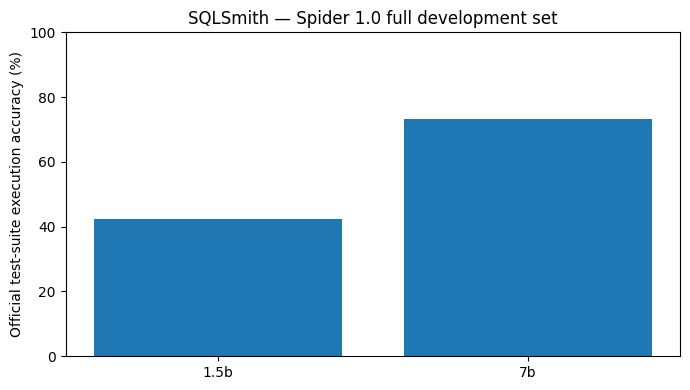

Report: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/full_spider/spider_full_dev_official_comparison.json
CSV: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/full_spider/spider_full_dev_model_comparison.csv
Chart: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/full_spider/spider_full_dev_accuracy.png


In [11]:
import matplotlib.pyplot as plt
report={
    'project':'SQLSmith', 'notebook':'06_Full_Spider_Benchmark',
    'evaluation_scope':'full Spider 1.0 dev', 'question_count':len(dev),
    'database_count':len(set(r['db_id'] for r in dev)),
    'model_results':EVAL_RESULTS,
    'accuracy_difference_percentage_points':round(100*(EVAL_RESULTS['7b']['accuracy']-EVAL_RESULTS['1.5b']['accuracy']),2),
    'evaluator_commit':EVALUATOR_COMMIT, 'plug_value':False, 'keep_distinct':False,
    'spider_dev_sha256':sha256_file(DEV_PATH),
    'table_metadata_sha256':sha256_file(TABLES_PATH),
    'test_suite_archive_sha256':sha256_file(ZIP),
    'gold_sha256':sha256_file(GOLD),
    'prediction_csv_sha256':{k:sha256_file(v) for k,v in PRED_CSVS.items()},
    'prediction_text_sha256':{k:sha256_file(v) for k,v in PRED_FILES.items()},
    'generated_at_utc':datetime.now(timezone.utc).isoformat(),
    'caveats':['Development-set evaluation, not independent test-set performance',
               'Quantized Colab latency measurements may not be directly comparable across sessions',
               'No fine-tuning or schema linking used']
}
REPORT_FILE=FULL/'spider_full_dev_official_comparison.json'
REPORT_FILE.write_text(json.dumps(report,indent=2),encoding='utf-8')
summary_rows=[]
for k in ('1.5b','7b'):
    frame=PRED_DFS[k]
    latency=pd.to_numeric(frame['latency_seconds'],errors='coerce')
    output_tokens=pd.to_numeric(frame['output_tokens'],errors='coerce')
    summary_rows.append({'model':k,'official_test_suite_accuracy':EVAL_RESULTS[k]['accuracy'],
        'mean_generation_latency_seconds':latency.mean(),
        'p95_generation_latency_seconds':latency.quantile(.95),
        'mean_generated_tokens_per_second':(output_tokens/latency).mean()})
summary_df=pd.DataFrame(summary_rows)
SUMMARY_CSV=FULL/'spider_full_dev_model_comparison.csv'
summary_df.to_csv(SUMMARY_CSV,index=False)
display(summary_df)
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(summary_df['model'],100*summary_df['official_test_suite_accuracy'])
ax.set_ylabel('Official test-suite execution accuracy (%)')
ax.set_ylim(0,100)
ax.set_title('SQLSmith — Spider 1.0 full development set')
fig.tight_layout()
CHART=FULL/'spider_full_dev_accuracy.png'
fig.savefig(CHART,dpi=170)
plt.show()
print('Report:',REPORT_FILE)
print('CSV:',SUMMARY_CSV)
print('Chart:',CHART)

## 14 — Final integrity verification / next research phase

Do not delete old 50-question artifacts. The expanded benchmark is a **new experiment**; Notebook 05 can be updated to incorporate these full-dev results later.

For statistical inference on a paired model difference, the aggregate score alone is insufficient. Collect official **per-question** pass/fail outcomes from a verified evaluator API/log before reporting paired confidence intervals or McNemar results. No significance claims are generated here.

In [12]:
assert len(PRED_DFS['1.5b'])==1034 and len(PRED_DFS['7b'])==1034
assert REPORT_FILE.is_file() and SUMMARY_CSV.is_file() and CHART.is_file()
assert set(EVAL_RESULTS)=={'1.5b','7b'}
assert sha256_file(GOLD)==report['gold_sha256']
print('PASS: complete and aligned full-development predictions')
print('PASS: official scores and machine-readable report saved')

PASS: complete and aligned full-development predictions
PASS: official scores and machine-readable report saved
